# Demo GA: rute distribusi ke gerai Indomaret/Alfamart di Kota Bandung

Notebook ini menjalankan satu skenario kecil (10 gerai) langkah demi langkah:
memuat matriks jarak jalan, memilih skenario, membandingkan **nearest neighbor**,
**Held-Karp** (optimum pasti), dan **Algoritma Genetika**, lalu memeriksa jaraknya ruas demi ruas.

Jalankan sel dari atas ke bawah dengan **Shift+Enter**. Notebook ini harus berada di folder proyek utama
(sejajar dengan `ga_rute/` dan `data/`), dengan kernel `.venv312`.

## 1. Memuat data dan kode

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.getcwd())          # agar paket ga_rute ditemukan
from ga_rute import konfig
from ga_rute.ga import jalankan_ga, panjang_rute
from ga_rute.baselines import nearest_neighbor, held_karp
from ga_rute.skenario import toko_dalam_zona, buat_skenario, submatriks, seed_skenario

# ---- ubah nilai di bawah untuk mencoba skenario lain ----
MEREK  = "indomaret"   # "indomaret" atau "alfamart"
GUDANG = 1             # 1, 2, atau 3
N      = 10            # 10 bisa dibandingkan dengan Held-Karp; 20 atau 30 tidak
K      = 1             # nomor skenario (1..100 dipakai di eksperimen utama)

D = np.load(f"data/matriks_{MEREK}.npy")
n_gudang = konfig.JUMLAH_GUDANG
print(f"Matriks jarak {MEREK}: {D.shape} = {n_gudang} gudang + {D.shape[0] - n_gudang} gerai")
print(f"Zona: gerai dengan jarak jalan <= {konfig.RADIUS_KM} km dari gudang")

Matriks jarak indomaret: (175, 175) = 3 gudang + 172 gerai
Zona: gerai dengan jarak jalan <= 8 km dari gudang


## 2. Memilih skenario

Toko dipilih acak dari zona di sekitar gudang. Seed dibuat dari nomor gudang, ukuran, dan nomor skenario,
sehingga skenario yang sama selalu menghasilkan toko yang sama.

In [2]:
g = GUDANG - 1
zona = toko_dalam_zona(D, g, range(n_gudang, D.shape[0]), konfig.RADIUS_KM)
seed = seed_skenario(GUDANG, N, K)
toko = buat_skenario(zona, N, seed)        # nomor baris di matriks D
Ds = submatriks(D, g, toko)                # matriks (N+1)x(N+1); indeks 0 = gudang

print(f"Gerai dalam zona gudang {GUDANG}: {len(zona)}   |   seed = {seed}")
print("Gerai terpilih (nomor baris di matriks):", toko.tolist())

berkas = f"data/{MEREK}.csv"
if os.path.exists(berkas):
    daftar = pd.read_csv(berkas)
    tampil = daftar.iloc[toko - n_gudang][["name", "lat", "lon"]].copy()
    tampil.insert(0, "kode", [f"T{i}" for i in range(1, N + 1)])
    display(tampil.reset_index(drop=True))

Gerai dalam zona gudang 1: 67   |   seed = 110001
Gerai terpilih (nomor baris di matriks): [15, 42, 75, 79, 119, 136, 140, 157, 167, 172]


,kode,name,lat,lon
0,T1,Indomaret,-6.932451,107.654516
1,T2,Indomaret,-6.931879,107.713930
2,T3,Indomaret,-6.930416,107.635383
3,T4,Indomaret,-6.912945,107.651637
4,T5,Indomaret,-6.939070,107.629343
5,T6,Indomaret,-6.902340,107.705113
6,T7,Indomaret,-6.959730,107.644264
7,T8,Indomaret,-6.919206,107.708546
8,T9,Indomaret,-6.923018,107.661830
9,T10,Indomaret,-6.943746,107.710560


## 3. Matriks jarak jalan (km)

Baris = asal, kolom = tujuan. **G** adalah gudang. Karena ada jalan satu arah, jarak A→B bisa berbeda dari B→A.

In [3]:
label = ["G"] + [f"T{i}" for i in range(1, N + 1)]
tabel_jarak = pd.DataFrame(Ds, index=label, columns=label)
display(tabel_jarak.round(2))

a, b = 1, 2
print(f"Contoh asimetri: T{a} -> T{b} = {Ds[a, b]:.2f} km, tetapi T{b} -> T{a} = {Ds[b, a]:.2f} km")

,G,T1,T2,T3,T4,T5,T6,T7,T8,T9,T10
G,0.00,5.12,3.78,8.45,7.09,7.98,5.31,7.19,4.41,5.33,3.89
T1,3.85,0.00,7.52,3.57,3.86,5.04,9.05,4.86,8.14,4.76,7.63
T2,6.08,8.55,0.00,11.59,8.84,11.41,3.99,10.63,1.55,7.08,2.13
T3,7.43,3.61,11.10,0.00,4.51,1.50,12.16,4.24,11.25,5.73,11.21
T4,5.74,4.35,8.71,4.90,0.00,5.93,8.03,6.88,7.60,2.23,9.52
T5,6.87,4.50,10.54,1.50,5.59,0.00,12.06,3.27,11.16,6.80,10.65
T6,6.51,9.53,3.86,12.01,8.31,12.39,0.00,11.61,2.31,7.51,5.99
T7,6.76,4.39,10.43,4.47,6.36,3.37,11.96,0.00,11.05,7.57,10.54
T8,5.60,8.63,1.55,11.10,7.86,11.49,2.44,10.70,0.00,6.60,3.68
T9,4.05,5.03,7.08,5.58,2.01,7.05,7.50,7.56,6.59,0.00,7.83


Contoh asimetri: T1 -> T2 = 7.52 km, tetapi T2 -> T1 = 8.55 km


## 4. Tiga cara mencari rute

- **Nearest neighbor**: selalu ke gerai terdekat berikutnya.
- **Held-Karp**: optimum pasti (hanya praktis untuk sekitar 15 gerai atau kurang).
- **Algoritma Genetika**: populasi 100 rute, 1.000 generasi.

In [4]:
rute_nn, km_nn = nearest_neighbor(Ds)
if N <= 12:
    rute_hk, km_hk = held_karp(Ds)
else:
    rute_hk, km_hk = None, None
    print("N terlalu besar untuk Held-Karp; bandingkan dengan OR-Tools di script 08_ortools.py")
rute_ga, km_ga, riwayat = jalankan_ga(Ds, konfig.UKURAN_POP, konfig.GENERASI, seed=seed)

acuan = km_hk if km_hk is not None else km_ga
hasil = [("Nearest neighbor", km_nn, rute_nn), ("Algoritma Genetika", km_ga, rute_ga)]
if km_hk is not None:
    hasil.insert(1, ("Held-Karp (optimum)", km_hk, rute_hk))
tabel = pd.DataFrame({
    "metode": [h[0] for h in hasil],
    "total_km": [round(h[1], 3) for h in hasil],
    "selisih_thd_acuan_%": [round(100 * (h[1] - acuan) / acuan, 2) for h in hasil],
    "rute": ["G > " + " > ".join(f"T{t}" for t in h[2]) + " > G" for h in hasil],
})
pd.set_option("display.max_colwidth", 120)
display(tabel)

,metode,total_km,selisih_thd_acuan_%,rute
0,Nearest neighbor,42.635,8.99,G > T2 > T8 > T6 > T10 > T1 > T3 > T5 > T7 > T4 > T9 > G
1,Held-Karp (optimum),39.120,0.00,G > T10 > T2 > T8 > T6 > T9 > T4 > T3 > T5 > T7 > T1 > G
2,Algoritma Genetika,39.120,0.00,G > T10 > T2 > T8 > T6 > T9 > T4 > T3 > T5 > T7 > T1 > G


## 5. Memeriksa jarak ruas demi ruas

Jumlah jarak tiap ruas harus sama dengan total yang dilaporkan. Ini cara memverifikasi hasil dengan tangan.

In [5]:
def tabel_ruas(Ds, rute):
    urut = [0] + list(rute) + [0]
    nama = lambda i: "G" if i == 0 else f"T{i}"
    baris = [(f"{nama(a)} -> {nama(b)}", Ds[a, b]) for a, b in zip(urut[:-1], urut[1:])]
    return pd.DataFrame(baris, columns=["ruas", "jarak_km"])

ruas = tabel_ruas(Ds, rute_ga)
display(ruas.round(3))
print(f"Jumlah ruas = {ruas.jarak_km.sum():.3f} km  |  total GA = {km_ga:.3f} km")
assert abs(ruas.jarak_km.sum() - km_ga) < 1e-6, "Jumlah ruas tidak cocok dengan total!"

,ruas,jarak_km
0,G -> T10,3.893
1,T10 -> T2,3.813
2,T2 -> T8,1.547
3,T8 -> T6,2.443
4,T6 -> T9,7.507
5,T9 -> T4,2.014
6,T4 -> T3,4.897
7,T3 -> T5,1.503
8,T5 -> T7,3.266
9,T7 -> T1,4.387


Jumlah ruas = 39.120 km  |  total GA = 39.120 km


## 6. Grafik konvergensi

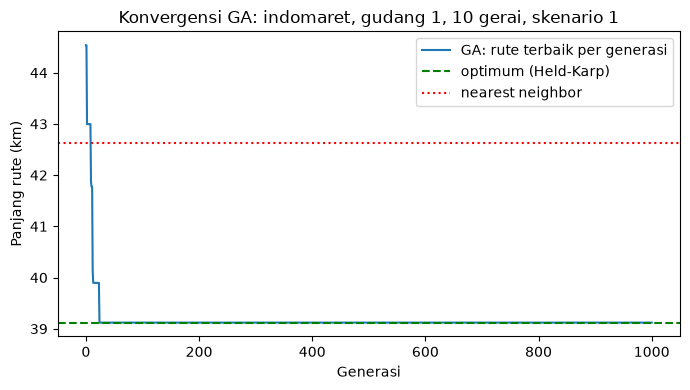

In [6]:
plt.figure(figsize=(7, 4))
plt.plot(riwayat, label="GA: rute terbaik per generasi")
if km_hk is not None:
    plt.axhline(km_hk, color="green", linestyle="--", label="optimum (Held-Karp)")
plt.axhline(km_nn, color="red", linestyle=":", label="nearest neighbor")
plt.xlabel("Generasi")
plt.ylabel("Panjang rute (km)")
plt.title(f"Konvergensi GA: {MEREK}, gudang {GUDANG}, {N} gerai, skenario {K}")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Ulangi untuk 10 skenario

Seberapa sering GA menemukan rute yang sama dengan optimum Held-Karp? (hanya untuk N kecil;
butuh sekitar satu menit)

In [7]:
if N <= 12:
    sama, selisih = 0, []
    for k in range(1, 11):
        sd = seed_skenario(GUDANG, N, k)
        Dk = submatriks(D, g, buat_skenario(zona, N, sd))
        _, ga_k, _ = jalankan_ga(Dk, konfig.UKURAN_POP, konfig.GENERASI, seed=sd)
        _, hk_k = held_karp(Dk)
        selisih.append(100 * (ga_k - hk_k) / hk_k)
        sama += ga_k <= hk_k + 1e-9
    print(f"GA mencapai optimum pada {sama} dari 10 skenario")
    print("Selisih ke optimum (%):", [round(s, 3) for s in selisih])
else:
    print("Lewati: gunakan N = 10 untuk bagian ini.")

GA mencapai optimum pada 10 dari 10 skenario
Selisih ke optimum (%): [0.0, 0.0, -0.0, 0.0, 0.0, 0.0, -0.0, 0.0, 0.0, 0.0]


## 8. Visualisasi hasil eksperimen

Sel-sel di bawah hanya membaca CSV di folder `hasil/` (keluaran `scripts/05_runner.py`, `08_ortools.py`,
`09_eksperimen_parameter.py`, dan `12_evaluasi_optimum.py`), jadi cepat dan tidak menjalankan GA lagi.
Warna: **biru = Indomaret**, **oranye = Alfamart**.

In [8]:
WARNA = {"indomaret": "#2a78d6", "alfamart": "#eb6834"}
ABU = "#6b6b6b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e4df", "grid.linewidth": 0.8})

def baca(nama):
    return pd.read_csv(f"hasil/{nama}.csv")

def kotak_per_merek(ax, data, kolom, ukuran):
    """Boxplot berdampingan: satu kotak per merek untuk tiap ukuran toko."""
    for j, merek in enumerate(WARNA):
        nilai = [data.loc[(data.merek == merek) & (data.n == n), kolom] for n in ukuran]
        posisi = [i + (j - 0.5) * 0.36 for i in range(len(ukuran))]
        ax.boxplot(nilai, positions=posisi, widths=0.3, patch_artist=True, showfliers=True,
                   boxprops=dict(facecolor=WARNA[merek], edgecolor=WARNA[merek], alpha=0.8),
                   medianprops=dict(color="white", linewidth=2),
                   whiskerprops=dict(color=WARNA[merek]), capprops=dict(color=WARNA[merek]),
                   flierprops=dict(marker="o", markersize=3, markerfacecolor=WARNA[merek],
                                   markeredgecolor="none", alpha=0.5))
        ax.plot([], [], "s", color=WARNA[merek], label=merek.capitalize())
    ax.set_xticks(range(len(ukuran)), [f"{n} toko" for n in ukuran])
    ax.legend(frameon=False)

### 8.1 Efisiensi: berapa evaluasi sampai optimum?

Untuk 600 skenario 10 toko (2 merek × 3 gudang × 100), dicatat evaluasi ke berapa GA pertama kali
menemukan optimum Held-Karp. Kurva naik = persentase skenario yang sudah optimal. Pembandingnya:
anggaran 100.000 evaluasi per run dan 10! = 3.628.800 urutan bila semua dicoba.

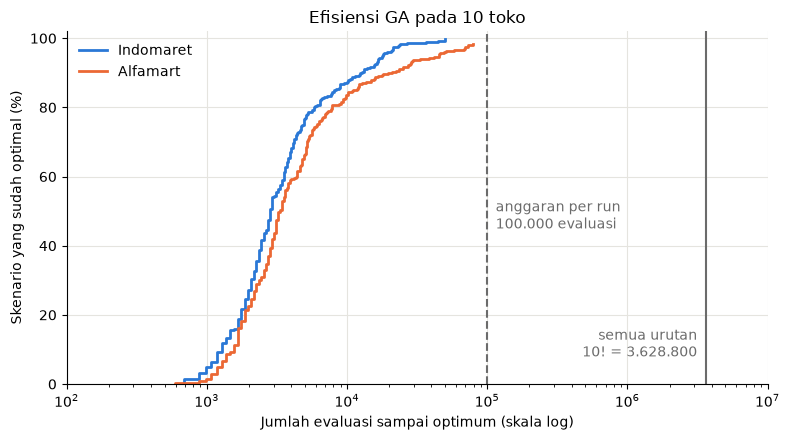

,optimal_%,median,p90,maks,median_%_ruang
merek,,,,,
alfamart,98.333,3236.0,15662.4,78696,0.089
indomaret,99.667,2844.0,12350.0,50178,0.078


In [9]:
from math import factorial

ev = baca("evaluasi_optimum")
anggaran = konfig.UKURAN_POP * konfig.GENERASI
fig, ax = plt.subplots(figsize=(8, 4.5))
for merek in WARNA:
    d = ev[ev.merek == merek]
    x = np.sort(d.evaluasi_optimum[d.evaluasi_optimum > 0])
    y = 100 * np.arange(1, len(x) + 1) / len(d)   # skenario gagal (-1) tetap masuk penyebut
    ax.step(np.r_[x[0], x], np.r_[0, y], where="post", color=WARNA[merek], lw=2, label=merek.capitalize())
ax.axvline(anggaran, color=ABU, ls="--", lw=1.5)
ax.axvline(factorial(10), color=ABU, lw=1.5)
ax.text(anggaran * 1.15, 45, f"anggaran per run\n{anggaran:,} evaluasi".replace(",", "."), color=ABU)
ax.text(factorial(10) / 1.15, 8, "semua urutan\n10! = 3.628.800", color=ABU, ha="right")
ax.set_xscale("log")
ax.set_xlim(100, 1e7)
ax.set_ylim(0, 102)
ax.set_xlabel("Jumlah evaluasi sampai optimum (skala log)")
ax.set_ylabel("Skenario yang sudah optimal (%)")
ax.set_title("Efisiensi GA pada 10 toko")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

ok = ev[ev.evaluasi_optimum > 0]
ringkas = ok.groupby("merek").evaluasi_optimum.agg(median="median", p90=lambda s: s.quantile(0.9), maks="max")
ringkas.insert(0, "optimal_%", 100 * ok.groupby("merek").size() / ev.groupby("merek").size())
ringkas["median_%_ruang"] = 100 * ringkas["median"] / factorial(10)
display(ringkas.round(3))

### 8.2 Efisiensi waktu: lama satu run GA

Satu run = 1.000 generasi × 100 individu = 100.000 evaluasi, untuk tiap skenario di eksperimen utama.

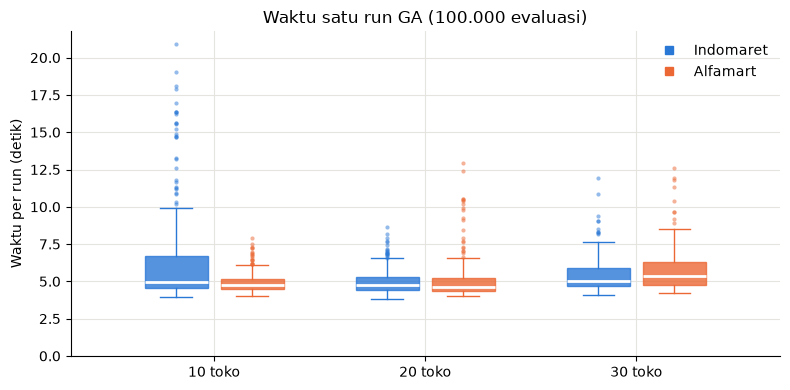

n,10,20,30
merek,,,
alfamart,4.76,4.61,5.34
indomaret,4.99,4.76,5.02


In [10]:
hasil = pd.concat([baca("hasil_indomaret"), baca("hasil_alfamart")], ignore_index=True)
fig, ax = plt.subplots(figsize=(8, 4))
kotak_per_merek(ax, hasil, "waktu_ga_s", [10, 20, 30])
ax.set_ylim(bottom=0)
ax.set_ylabel("Waktu per run (detik)")
ax.set_title("Waktu satu run GA (100.000 evaluasi)")
plt.tight_layout()
plt.show()
display(hasil.groupby(["merek", "n"]).waktu_ga_s.median().unstack().round(2))

### 8.3 Penghematan GA dibanding nearest neighbor

Tiap titik data = satu skenario: (NN − GA) / NN × 100. Nilai positif berarti rute GA lebih pendek.

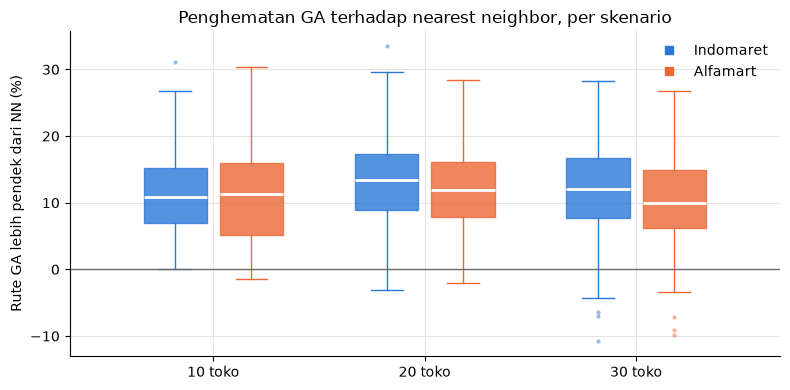

n,10,20,30
merek,,,
alfamart,11.27,11.93,9.9
indomaret,10.88,13.44,12.1


In [11]:
hasil["hemat_pct"] = 100 * (hasil.nn_km - hasil.ga_km) / hasil.nn_km
fig, ax = plt.subplots(figsize=(8, 4))
kotak_per_merek(ax, hasil, "hemat_pct", [10, 20, 30])
ax.axhline(0, color=ABU, lw=1)
ax.set_ylabel("Rute GA lebih pendek dari NN (%)")
ax.set_title("Penghematan GA terhadap nearest neighbor, per skenario")
plt.tight_layout()
plt.show()
display(hasil.groupby(["merek", "n"]).hemat_pct.median().unstack().round(2))

### 8.4 Jarak GA ke OR-Tools (20 dan 30 toko)

Gap = (GA − OR-Tools) / OR-Tools × 100. OR-Tools dibatasi waktu, jadi bukan optimum pasti;
gap negatif berarti GA lebih baik.

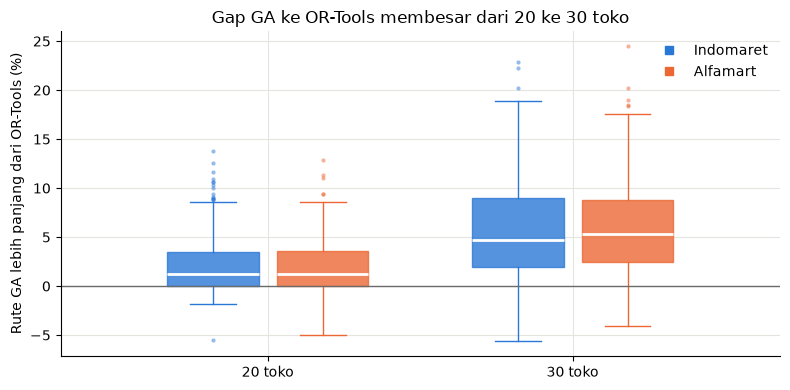

n,20,30
merek,,
alfamart,1.28,5.29
indomaret,1.22,4.70


In [12]:
ortools = pd.concat([baca("ortools_indomaret"), baca("ortools_alfamart")], ignore_index=True)
gap = hasil.merge(ortools, on=["merek", "gudang", "n", "skenario"])
gap["gap_pct"] = 100 * (gap.ga_km - gap.or_km) / gap.or_km
fig, ax = plt.subplots(figsize=(8, 4))
kotak_per_merek(ax, gap, "gap_pct", [20, 30])
ax.axhline(0, color=ABU, lw=1)
ax.set_ylabel("Rute GA lebih panjang dari OR-Tools (%)")
ax.set_title("Gap GA ke OR-Tools membesar dari 20 ke 30 toko")
plt.tight_layout()
plt.show()
display(gap.groupby(["merek", "n"]).gap_pct.median().unstack().round(2))

### 8.5 Eksperimen parameter (Indomaret, 30 toko)

Satu faktor diubah dari konfigurasi dasar, anggaran tetap 100.000 evaluasi. Batang biru = konfigurasi dasar yang dipakai.

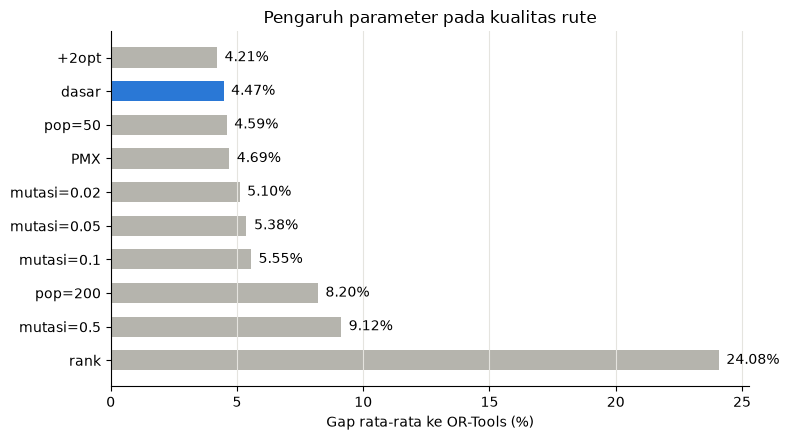

In [13]:
par = baca("ringkasan_parameter_indomaret_n30").sort_values("gap_rata_pct", ascending=False)
warna = [WARNA["indomaret"] if k == "dasar" else "#b5b4ad" for k in par.konfigurasi]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(par.konfigurasi, par.gap_rata_pct, color=warna, height=0.6)
for y, v in enumerate(par.gap_rata_pct):
    ax.text(v + 0.3, y, f"{v:.2f}%", va="center")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Gap rata-rata ke OR-Tools (%)")
ax.set_title("Pengaruh parameter pada kualitas rute")
plt.tight_layout()
plt.show()

## 9. Coba sendiri: pilih gerai, GA mencari rutenya

Pilih gudang dan nomor gerai yang ingin dikunjungi. GA lalu mencari **urutan kunjungan** dengan total jarak jalan
terpendek, memakai matriks jarak Dijkstra yang sama dengan eksperimen. Nomor gerai = nomor baris di
`data/<merek>.csv` (mulai dari 1), terlihat di peta berikut.

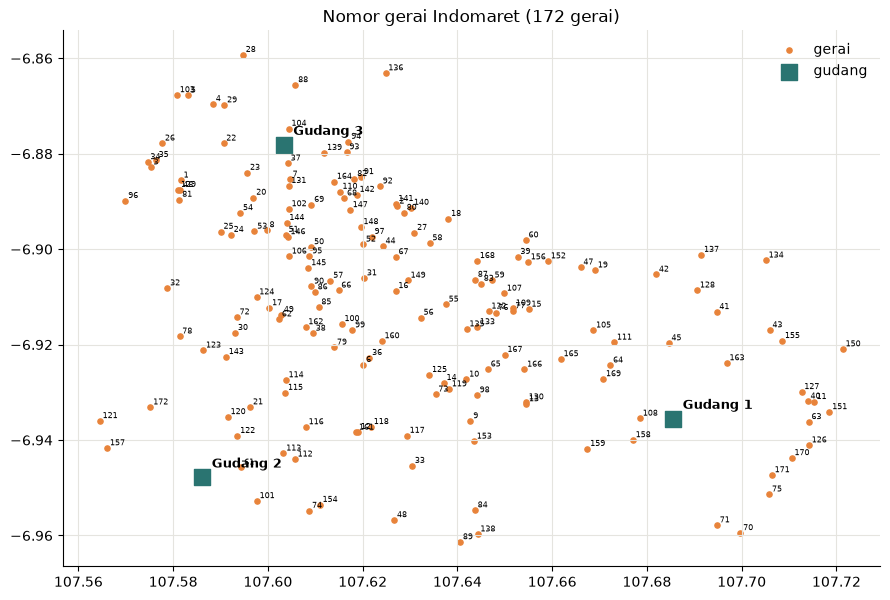

In [14]:
MEREK_DEMO = "indomaret"   # "indomaret" atau "alfamart"

D_demo = np.load(f"data/matriks_{MEREK_DEMO}.npy")
gerai_df = pd.read_csv(f"data/{MEREK_DEMO}.csv")
gudang_df = pd.read_csv("data/gudang.csv")

fig, ax = plt.subplots(figsize=(9, 9))
ax.scatter(gerai_df.lon, gerai_df.lat, s=14, color="#e8833a", label="gerai")
for i, (x, y) in enumerate(zip(gerai_df.lon, gerai_df.lat), start=1):
    ax.annotate(str(i), (x, y), xytext=(2, 2), textcoords="offset points", fontsize=6)
ax.scatter(gudang_df.lon, gudang_df.lat, s=140, marker="s", color="#2a7471", label="gudang")
for i, (x, y) in enumerate(zip(gudang_df.lon, gudang_df.lat), start=1):
    ax.annotate(f"Gudang {i}", (x, y), xytext=(7, 7), textcoords="offset points", fontsize=9, fontweight="bold")
ax.set_aspect(1 / np.cos(np.radians(gerai_df.lat.mean())))
ax.set_title(f"Nomor gerai {MEREK_DEMO.capitalize()} ({len(gerai_df)} gerai)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Daftar gudang ada di tabel berikut dan di dropdown **Gudang**. Pilih gerai di daftar (**Ctrl + klik** atau
**Shift + klik** untuk beberapa gerai), lalu tekan **Cari rute**. Untuk 12 gerai atau kurang, hasil GA juga
dibandingkan dengan optimum pasti Held-Karp. Memuat peta jalan butuh sekitar satu menit pada klik pertama.
Untuk ganti merek, ubah `MEREK_DEMO` di sel peta di atas.

In [15]:
import ipywidgets as w
import osmnx as ox
from ga_rute.data import simpul_terdekat
from ga_rute.visual import jalur_rute

daftar_gudang = gudang_df.copy()
daftar_gudang.insert(0, "gudang", range(1, len(gudang_df) + 1))
daftar_gudang[f"gerai ≤ {konfig.RADIUS_KM} km"] = [
    len(toko_dalam_zona(D_demo, g, range(konfig.JUMLAH_GUDANG, D_demo.shape[0]), konfig.RADIUS_KM))
    for g in range(len(gudang_df))]
display(daftar_gudang)


def cari_rute(gudang, pilihan, peta=True):
    """Jalankan GA untuk gudang dan nomor gerai pilihan; tampilkan rute, tabel, dan peta jalan."""
    global G_jalan
    Dd = submatriks(D_demo, gudang - 1, [konfig.JUMLAH_GUDANG + p - 1 for p in pilihan])  # 3 gudang dulu, lalu gerai
    rute, km, _ = jalankan_ga(Dd, konfig.UKURAN_POP, konfig.GENERASI, seed=1)
    rute_nn, km_nn = nearest_neighbor(Dd)

    nama = lambda i: "Gudang" if i == 0 else f"#{pilihan[i - 1]}"
    print("Rute GA :", " → ".join(nama(i) for i in [0, *rute, 0]))
    print(f"Total GA: {km:.2f} km  |  nearest neighbor: {km_nn:.2f} km  "
          f"(GA {100 * (km_nn - km) / km_nn:.1f}% lebih pendek)")
    if len(pilihan) <= 12:
        _, km_hk = held_karp(Dd)
        selisih = 100 * (km - km_hk) / km_hk
        print(f"Optimum Held-Karp: {km_hk:.2f} km  ->  "
              + ("GA sama dengan optimum" if selisih < 1e-9 else f"GA {selisih:.2f}% di atas optimum"))

    urutan = pd.DataFrame({"ke": range(1, len(rute) + 1), "gerai": [pilihan[i - 1] for i in rute]})
    urutan[["lat", "lon"]] = gerai_df.iloc[urutan.gerai - 1][["lat", "lon"]].values
    display(urutan)

    if peta:
        if "G_jalan" not in globals():
            print("Memuat peta jalan ...")
            G_jalan = ox.load_graphml("data/jalan_bandung.graphml")
        idx = np.array(pilihan) - 1
        lon = np.r_[gudang_df.lon.iloc[gudang - 1], gerai_df.lon.values[idx]]
        lat = np.r_[gudang_df.lat.iloc[gudang - 1], gerai_df.lat.values[idx]]
        simpul, _ = simpul_terdekat(G_jalan, lon, lat)
        fig, ax = plt.subplots(figsize=(9, 8))
        for r, warna, lebar, label in [(rute_nn, "#d1495b", 1.5, f"Nearest neighbor: {km_nn:.2f} km"),
                                       (rute, "#14213d", 2.5, f"Algoritma Genetika: {km:.2f} km")]:
            xs, ys = jalur_rute(G_jalan, simpul, r)
            ax.plot(xs, ys, color=warna, lw=lebar, alpha=0.85, label=label)
        ax.scatter(lon[1:], lat[1:], s=60, color="#e8833a", edgecolor="white", zorder=4)
        ax.scatter(lon[:1], lat[:1], s=140, marker="s", color="#2a7471", edgecolor="white", zorder=5)
        for p, x, y in zip(pilihan, lon[1:], lat[1:]):
            ax.annotate(f"#{p}", (x, y), xytext=(4, 4), textcoords="offset points", fontsize=8)
        ax.set_aspect(1 / np.cos(np.radians(lat.mean())))
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(f"Gudang {gudang} dan {len(pilihan)} gerai pilihan")
        ax.legend(frameon=False, loc="best")
        plt.tight_layout()
        plt.show()
    return rute, km


gaya = {"description_width": "70px"}
pilih_gudang = w.Dropdown(options=[(f"{i} · {n}", i) for i, n in enumerate(gudang_df.nama, start=1)],
                          value=1, description="Gudang", style=gaya, layout=w.Layout(width="380px"))
pilih_gerai = w.SelectMultiple(options=[(f"Gerai {i}", i) for i in range(1, len(gerai_df) + 1)],
                               value=(5, 18, 33, 47, 60, 72, 95, 110), rows=12, description="Gerai",
                               style=gaya, layout=w.Layout(width="380px"))
pakai_peta = w.Checkbox(value=True, description="Tampilkan peta jalan", indent=False)
tombol = w.Button(description="Cari rute", button_style="primary", icon="search", layout=w.Layout(width="160px"))
info = w.HTML()
keluaran = w.Output()


def perbarui_info(_=None):
    info.value = f"<b>{len(pilih_gerai.value)}</b> gerai dipilih: {', '.join(map(str, pilih_gerai.value))}"


def saat_klik(_):
    keluaran.clear_output()
    with keluaran:
        pilihan = list(pilih_gerai.value)
        if len(pilihan) < 2:
            print("Pilih minimal 2 gerai (Ctrl + klik atau Shift + klik).")
            return
        tombol.disabled, tombol.description = True, "Menghitung ..."
        try:
            cari_rute(pilih_gudang.value, pilihan, pakai_peta.value)
        finally:
            tombol.disabled, tombol.description = False, "Cari rute"


pilih_gerai.observe(perbarui_info, names="value")
tombol.on_click(saat_klik)
perbarui_info()
display(w.VBox([pilih_gudang, pilih_gerai, info, w.HBox([tombol, pakai_peta]), keluaran]))

,gudang,nama,lat,lon,gerai ≤ 8 km
0,1,Gudang Timur (area Gedebage),-6.9355,107.6855,67
1,2,Gudang Barat (area Kopo),-6.9478,107.5861,67
2,3,Gudang Utara (area Setiabudi),-6.8781,107.6033,103


## Catatan

- Hasil GA bergantung pada seed dan sedikit berbeda antar komputer untuk N besar (lihat bagian keterbatasan di `DOKUMENTASI.md`).
- Untuk 20 dan 30 gerai, patokan yang dipakai adalah OR-Tools (`scripts/08_ortools.py`).
- Seluruh eksperimen utama dijalankan oleh `scripts/05_runner.py`; bagian 1–7 notebook ini hanya melihat satu skenario, sedangkan bagian 8 membaca hasilnya dari `hasil/`.